# 8.1 Суррогат теплопроводности / 热导率代理模型
Учебные данные задаём формулой. Это не эксперимент и не модель конкретного материала.
用公式生成教学数据，不代表实验结果或某种真实材料。使用 NumPy、Matplotlib 和 PyTorch。

In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 110})
blue, red = "#356AE6", "#D94F65"
import copy
import torch
from torch import nn
torch.set_num_threads(1)
torch.manual_seed(0)
rng = np.random.default_rng(0)

Matplotlib is building the font cache; this may take a moment.


## Данные / 数据
$\kappa(T,L)=\frac{200}{1+0.0005(T-300)^2}\exp(-L/200)$.
$T$: 100–600 K, $L$: 10–500 nm. Масштабируем входы по этим границам, выход делим на 100.
温度范围 100–600 K，长度范围 10–500 nm。按给定范围缩放输入，输出除以 100。

In [2]:
def kappa_reference(T, L):
    return 200 / (1 + 0.0005 * (T - 300)**2) * np.exp(-L / 200)

T = rng.uniform(100, 600, 1000)
L = rng.uniform(10, 500, 1000)
features = np.column_stack([T, L])
kappa = kappa_reference(T, L)
X = torch.tensor((features - [100, 10]) / [500, 490], dtype=torch.float32)
y = torch.tensor(kappa[:, None] / 100, dtype=torch.float32)
order = rng.permutation(len(X))
train, valid, test = order[:700], order[700:850], order[850:]
print("Train / validation / test:", len(train), len(valid), len(test))

Train / validation / test: 700 150 150


## Обучение / 训练
Сеть 2 → 32 → 32 → 1, ReLU, Adam. Выбираем эпоху по validation; test используем только для итоговой оценки.
采用两层 32 单元 ReLU 网络和 Adam。用验证集选择模型，测试集只用于最终评估。

In [3]:
class KappaNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, 32), nn.ReLU(),
            nn.Linear(32, 32), nn.ReLU(), nn.Linear(32, 1))

    def forward(self, x):
        return self.net(x)

model = KappaNet()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
history, best_loss = [], float("inf")
for epoch in range(2000):
    model.train()
    for batch in torch.tensor(train)[torch.randperm(len(train))].split(64):
        loss = ((model(X[batch]) - y[batch])**2).mean()
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    model.eval()
    with torch.no_grad():
        train_loss = ((model(X[train]) - y[train])**2).mean().item()
        valid_loss = ((model(X[valid]) - y[valid])**2).mean().item()
    history.append([train_loss, valid_loss])
    if valid_loss < best_loss:
        best_loss, best_epoch = valid_loss, epoch + 1
        best_state = copy.deepcopy(model.state_dict())
model.load_state_dict(best_state)
history = np.asarray(history)

Best epoch: 747; test RMSE: 1.296; MAE: 0.921 W/(m K)


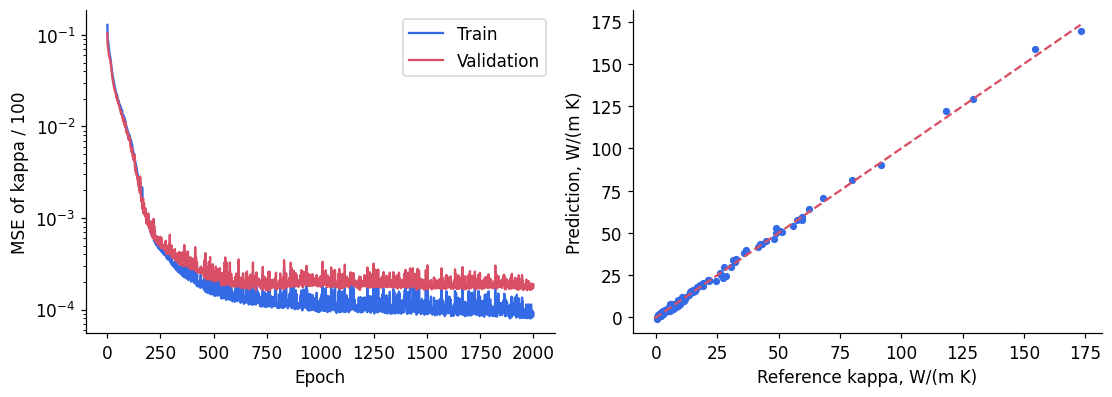

In [4]:
def predict_kappa(T, L):
    inputs = np.column_stack([np.asarray(T).ravel(), np.asarray(L).ravel()])
    inputs = torch.tensor((inputs - [100, 10]) / [500, 490], dtype=torch.float32)
    with torch.no_grad():
        return model(inputs).numpy().ravel() * 100

prediction = predict_kappa(T[test], L[test])
rmse = np.sqrt(np.mean((prediction - kappa[test])**2))
mae = np.mean(np.abs(prediction - kappa[test]))
print(f"Best epoch: {best_epoch}; test RMSE: {rmse:.3f}; MAE: {mae:.3f} W/(m K)")
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), layout="constrained")
axes[0].semilogy(np.arange(1, 2001), history[:, 0], label="Train", color=blue)
axes[0].semilogy(np.arange(1, 2001), history[:, 1], label="Validation", color=red)
axes[0].set(xlabel="Epoch", ylabel="MSE of kappa / 100")
axes[0].legend()
axes[1].scatter(kappa[test], prediction, s=14, color=blue)
limits = [min(0, prediction.min()), max(kappa[test].max(), prediction.max())]
axes[1].plot(limits, limits, "--", color=red)
axes[1].set(xlabel="Reference kappa, W/(m K)", ylabel="Prediction, W/(m K)")
plt.show()

## За пределами данных / 数据范围之外
Фиксируем L = 100 nm и расширяем диапазон температуры. Даже малая ошибка test не гарантирует правильной экстраполяции.
固定长度为 100 nm，扩大温度范围。测试误差很小，也不能保证外推正确；保留网络的原始预测，不裁剪负值。

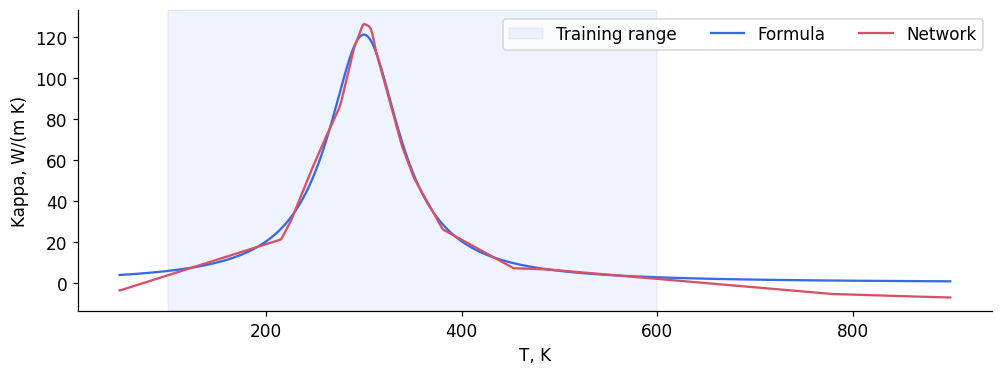

In [5]:
temperature = np.linspace(50, 900, 500)
length = np.full_like(temperature, 100)
fig, ax = plt.subplots(figsize=(9, 3.3), layout="constrained")
ax.axvspan(100, 600, color=blue, alpha=0.08, label="Training range")
ax.plot(temperature, kappa_reference(temperature, length), color=blue, label="Formula")
ax.plot(temperature, predict_kappa(temperature, length), color=red, label="Network")
ax.set(xlabel="T, K", ylabel="Kappa, W/(m K)")
ax.legend(ncol=3)
plt.show()